# Jev alone as a judge — direct TypeSafe API

This notebook runs the first stage of the [Jev/LLM comparison](llm_as_judge.ipynb).
It evaluates the same 300 routing traces against the human `Vague_Utterance_Failure` label:
**was this routing mistake caused specifically by a vague utterance?** A `FALSE` answer
also includes routing mistakes caused by other failure modes.

**Replay is ready:** the repository contains 300 real TypeSafe responses, a frozen split,
and the cost-estimation metadata. Replay makes no API calls and needs no key. Live mode
uses `TYPESAFE_API_KEY`; it requires no OpenRouter account. The independent LLM and cascade
are separate experiments in the comparison notebook and need an LLM provider credential.

Jev is a candidate for a quick, narrow “System 1” judgment: it returns a typed decision
without generating an explanation. That design can lower cost, but usefulness still depends
on agreement with an explicit rubric and the failures the application needs to catch.
See [TypeSafe's introduction](https://docs.typesafe.ai/introduction).

In [1]:
# Run from this directory, the repository root, or a fresh Colab runtime.
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_REF = os.environ.get("ROUTING_EVALS_REF", "codex/jev-routing-judge")
candidates = [Path.cwd(), Path.cwd() / "routing_agent_evals",
              Path.cwd() / "AI-Evals-Principles/routing_agent_evals"]
LAB = next((p for p in candidates if (p / "judge_lab.py").exists()), None)
if LAB is None and IN_COLAB:
    checkout = Path("/content/routing-evals-lab")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_REF,
                        "https://github.com/The-Gen-Academy/Mastering-Agentic-AI-Week4-Session1.git",
                        str(checkout)], check=True)
    LAB = checkout / "AI-Evals-Principles/routing_agent_evals"
if LAB is None or not (LAB / "judge_lab.py").exists():
    raise RuntimeError("Open the notebook from its repository checkout; see README for setup.")
LAB = LAB.resolve()
os.chdir(LAB)
sys.path.insert(0, str(LAB))
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pandas", "scikit-learn", "matplotlib", "python-dotenv"], check=True)

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
from judge_lab import (JudgeClient, load_dataset, split_dataset, batch, metrics,
                       always_false, request_for, save_json, digest, POLICY, CRITERIA)

load_dotenv(LAB / ".env", override=False)
EVIDENCE = Path(os.environ.get("JUDGE_EVIDENCE_DIR", str(LAB / "data/jev_judge_run")))
MODE = os.environ.get("JEV_MODE", "replay" if (EVIDENCE / "jev_manifest.json").exists() else "live")
assert MODE in {"replay", "live"}
RUN = Path(os.environ.get("JEV_RUN_DIR", str(LAB / ".runs/jev")))
RUN.mkdir(parents=True, exist_ok=True)
manifest = json.loads((EVIDENCE / "jev_manifest.json").read_text()) if MODE == "replay" else {}
client = JudgeClient(EVIDENCE / "cache" if MODE == "replay" else RUN / "cache",
                     live=(MODE == "live"), providers=manifest.get("providers"),
                     models=manifest.get("models"), pricing=manifest.get("pricing"))
if MODE == "live":
    key = os.environ.get("TYPESAFE_API_KEY")
    if not key and IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("TYPESAFE_API_KEY")
        except Exception:
            pass
    if not key:
        from getpass import getpass
        key = getpass("TYPESAFE_API_KEY (hidden, never saved): ").strip()
    client.api_keys["jev"] = key
print("Mode:", MODE, "| Jev model:", client.models["jev"], "| provider:", client.providers["jev"])

Mode: replay | Jev model: jev-1.13.0 | provider: typesafe


## Freeze the task and split

Both this notebook and the comparison use the original intent rules and vague-utterance
policy. Only the query and candidate intent enter the request; human labels, target intents,
and comments are withheld. The deterministic, stratified, query-grouped split reserves
100 calibration cases and 200 held-out cases. We do not revise the policy based on held-out
results. The comparison chooses its confidence threshold using calibration data only.

There are just 20 positive human labels in the full dataset. Always answering `FALSE`
therefore achieves 93.3% agreement while detecting none of the labeled failures. Accuracy
must be read alongside positive-class recall and F1. Labels are preserved as supplied;
see the comparison notebook for cross-file data conflicts and sensitivity analysis.

In [3]:
rows = load_dataset(LAB / "data")
calibration, heldout = split_dataset(rows)
display(pd.DataFrame([{"split": name, "rows": len(part),
                      "positive_labels": sum(r["human_label"] == "TRUE" for r in part)}
                     for name, part in [("Calibration", calibration), ("Held out", heldout)]]))
print("Dataset hash:", digest(rows))
example_request = request_for(calibration[0], "jev", client.models["jev"])
print("State sent to Jev:", example_request["state"])
assert set(example_request["state"]) == {"user_query", "predicted_intent"}
display(pd.DataFrame([{"choice": k, "criterion": v} for k, v in CRITERIA.items()]))

,split,rows,positive_labels
0,Calibration,100,7
1,Held out,200,13


Dataset hash: c5f9c5d5989767cd69b2d39ba7651457f670792bbfc9097bed62069170e4a8f1
State sent to Jev: {'user_query': 'Cancel my 10:00 - 10:30 patient Monday', 'predicted_intent': 'UNSUPPORTED_REQUEST'}


,choice,criterion
0,TRUE,The predicted intent is wrong specifically bec...
1,FALSE,"The predicted intent is correct, or it is wron..."


## Jev chooses a label; confidence controls review

This is **Choice**, with `TRUE` and `FALSE` options. Jev returns a selected label, probabilities,
and confidence. We use the label directly. It is not the ordered-rubric **Score** primitive
and there is no weighted-average or 1–5 conversion in this experiment.

For binary Choice, `confidence = 2 × max(probabilities) − 1`. Probabilities 0.85 / 0.15
therefore give confidence 0.70. Confidence is distinct from the winning-option probability
and is not a guarantee of accuracy. See [Choice](https://docs.typesafe.ai/primitives/choice)
and [confidence](https://docs.typesafe.ai/confidence).

In [4]:
jev_cal = batch(calibration, lambda r: client.call(r, "jev"))
jev_test = batch(heldout, lambda r: client.call(r, "jev"))
jev = {**jev_cal, **jev_test}
display(pd.DataFrame([jev_cal[calibration[0]["id"]]]))
comparison = pd.DataFrame([metrics(heldout, values, name) for name, values in
                          [("Always FALSE", always_false(heldout)), ("Jev held out", jev_test)]])
display(comparison[["method", "n", "accuracy", "precision_TRUE", "recall_TRUE", "f1_TRUE",
                    "TN", "FP", "FN_including_unresolved", "TP", "unresolved"]])
comparison.to_csv(RUN / "jev-heldout-comparison.csv", index=False)

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,confidence,probabilities,model
0,TEST_016,jev,376b850973bcd023e1597bbb6ad81b4685e036b530bd60...,0.000056,0,0.000056,1,0,1,1,0.099805,1328,33,FALSE,None,1.0,"{'TRUE': 0.0, 'FALSE': 1.0}",jev-1.13.0


,method,n,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved
0,Always FALSE,200,0.935,0.0,0.0,0,187,0,13,0,0
1,Jev held out,200,0.895,0.0,0.0,0,179,8,13,0,0


## Token usage and estimated cost

TypeSafe returned input/output token counts without a billed USD amount. The published
Jev 1.13 rate, checked 2026-10-22, is **$0.042 per million input tokens; output tokens are
free**. We freeze that rate and its [source](https://docs.typesafe.ai/models) in the manifest.
`estimated_cost_usd` is token usage multiplied by this rate, not an invoice; credits and
account-specific discounts are excluded. `reported_cost_usd` records any explicit provider
charge. Missing usage or an unknown model price remains unknown, never zero by assumption.

The comparison notebook uses `Jev cost for all rows + LLM cost for escalated rows` for
cascade deployment cost. The full research benchmark also incurs standalone LLM and
calibration calls. This Jev-only notebook cannot establish cascade savings or quality.

,method,n,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,USD_per_1000_including_estimates
0,Calibration,100,0,0.005548,100,0,0.055479
1,Held out,200,0,0.011103,200,0,0.055517
2,All Jev requests,300,0,0.016651,300,0,0.055504


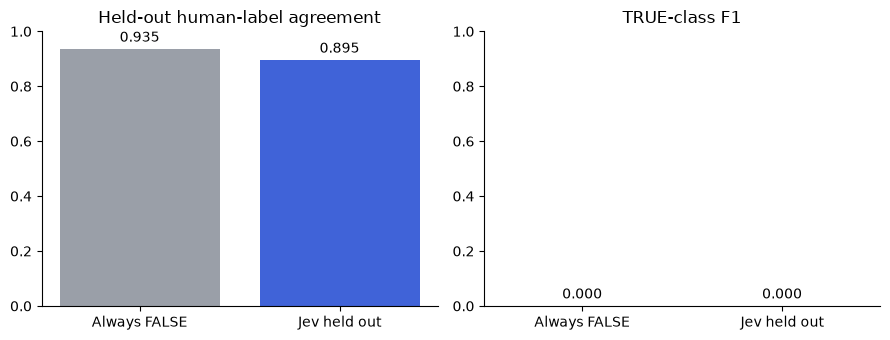

In [5]:
costs = pd.DataFrame([metrics(part, jev, name) for name, part in
                      [("Calibration", calibration), ("Held out", heldout), ("All Jev requests", rows)]])
costs["USD_per_1000_including_estimates"] = costs.cost_usd / costs.n * 1000
display(costs[["method", "n", "reported_cost_usd", "estimated_cost_usd",
               "estimated_cost_attempts", "unknown_cost_attempts", "USD_per_1000_including_estimates"]])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, field, title in zip(axes, ["accuracy", "f1_TRUE"], ["Held-out human-label agreement", "TRUE-class F1"]):
    bars = ax.bar(comparison.method, comparison[field], color=["#9a9fa8", "#4063d8"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Read the result before adopting the judge

In the recorded run, Jev agreed with **179/200 held-out labels (89.5%)**, but detected
**0/13** positive examples. The always-FALSE baseline agreed with **187/200 (93.5%)**.
The all-300-request Jev cost estimate is **$0.01665**. These are measurements of this frozen
policy and the supplied labels; they do not establish performance on other tasks.

This run does **not** support deploying Jev alone for detecting these vague-utterance
failures. A confidence gate can help only if it sends the relevant mistakes to a more
accurate second judge. Confident mistakes bypass that gate. The next notebook measures
LLM fixes and regressions, high/low-confidence subsets, and rare-class recall. The recorded comparison is complete: its 0.70 gate escalates 39/200 traces, detects 5/13
failures, and costs an estimated 69.0% less than LLM alone. It also lowers agreement
relative to Jev alone, so read the full tradeoff analysis before adopting the policy.

If labels or the rubric need revision, review calibration examples and create a new held-out
set for the next experiment. Do not tune against the held-out labels shown here.

In [6]:
summary = {"dataset_hash": digest(rows), "policy_hash": digest([POLICY, CRITERIA]),
           **client.configuration(),
           "calibration_ids": [r["id"] for r in calibration],
           "heldout_ids": [r["id"] for r in heldout],
           "calibration_metrics": metrics(calibration, jev, "Jev calibration"),
           "heldout_metrics": metrics(heldout, jev, "Jev held out"),
           "full_dataset_metrics": metrics(rows, jev, "Jev full dataset")}
if MODE == "replay":
    for field in ("dataset_hash", "policy_hash", "calibration_ids", "heldout_ids",
                  "calibration_metrics", "heldout_metrics", "full_dataset_metrics"):
        assert summary[field] == manifest[field], field
    assert client.new_requests == 0
else:
    save_json(RUN / "jev_manifest.json", summary)
save_json(RUN / "summary.json", summary)
print("Jev notebook complete; fresh HTTP requests:", client.new_requests)
print("Outputs:", RUN)

Jev notebook complete; fresh HTTP requests: 0
Outputs: routing_agent_evals/.runs/jev
